# Exploratory Data Analysis - NTSB aviation cases

This notebook performs EDA of aviation cases from NTSB public API.

The analysis focuses on exploring potential input data and labels for developing a model, which will be able to infer events leading to and/or causes of an aviation incident.

## Conclusions
`analysisNarrative` is chosen as input for the model
Characteristics:
- It's available in 67.5% of the dataset
- It's available only for completed investigations (100% of Completed cases, 0% of N/A and Ongoing cases)
- The median length is 160 words (maximum 5879), much shorter than the factual narrative

`Events` are chosen as labels for learning.
- Have the best availability (99.7%)
- 8155 of 8269 cases have exactly one defining event, so it fits multiclass classification
- In 87% of cases the defining event is the first event in the sequence
- Defining events fall into 36 CICTT occurrence categories, 28 of them have at least 20 cases

`Findings` could potentially be used as labels as well. 
Tier 1 findings have only 5 categories, while tier 2 have 21, the next tiers have too many distinct labels therefore are not suitable for multilabel classification.


- `Factual narrative` is very long (median 681 words), available only in 27.6% of cases -> not chosen
- `Preliminary analysis` is available only in 5.4% of cases -> not chosen
- `Probable Cause` has the best availability out of all text fields (67.5%), however the median text length is only 21 words. Paired with findings it wouldn't pose a big challenge for the model.



## Setup and loading

In [586]:
import json
import re

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

In [587]:
with open("ntsb_cases.json", encoding="utf-8") as file:
    raw_cases = json.load(file)

In [588]:
print("Number of cases:", len(raw_cases))

Number of cases: 8270


In [589]:
cases_with_several_narratives = 0
cases_with_several_aircraft = 0
for case in raw_cases:
    narratives = case.get("narratives") or []
    aircraft_list = case.get("aircrafts") or []
    if len(narratives) > 1:
        cases_with_several_narratives += 1
    if len(aircraft_list) > 1:
        cases_with_several_aircraft += 1

In [590]:
print("Cases with more than one narrative record:", cases_with_several_narratives)
print("Cases with more than one aircraft:", cases_with_several_aircraft)

Cases with more than one narrative record: 0
Cases with more than one aircraft: 163


In [591]:
def clean_text(value):
    if isinstance(value, str) and value.strip() != "":
        return value.strip()
    return None

In [592]:
TEXT_FIELDS = {
    "probableCause": "probableCause",
    "factualNarrative": "concatenatedFactualNarrative",
    "analysisNarrative": "analysisNarrative",
    "prelimNarrative": "prelimNarrative",
}
FINDING_COLUMNS = ["findingNumber", "findingCode", "findingDescription", "inProbableCause",
                   "tier1Name", "tier2Name", "tier3Name", "tier4Name", "modifierName"]
EVENT_COLUMNS = ["eventNumber", "sequenceNumber", "eventCode", "eventTier1Name", "eventTier2Name",
                 "cicttPhaseSOEGroup", "cicttEventSOEGroup", "isDefiningEvent"]
CASE_COLUMNS = ["mKey", "ntsbNumber", "eventDate", "eventType", "completionStatus",
                "investigationClass", "highestInjuryLevel", "caseType"]

In [593]:
case_rows = []
finding_rows = []
event_rows = []

for case in raw_cases:
    narratives = case.get("narratives") or []
    if len(narratives) > 0:
        narrative = narratives[0]
    else:
        narrative = {}

    aircraft_list = case.get("aircrafts") or []

    case_row = {}
    for column in CASE_COLUMNS:
        case_row[column] = case.get(column)
    case_row["numberOfAircraft"] = len(aircraft_list)
    for field_name, json_key in TEXT_FIELDS.items():
        case_row[field_name] = clean_text(narrative.get(json_key))
    case_rows.append(case_row)

    for aircraft in aircraft_list:
        for finding in aircraft.get("findings") or []:
            finding_row = {"mKey": case["mKey"], "aircraftNumber": aircraft.get("aircraftNumber")}
            for column in FINDING_COLUMNS:
                finding_row[column] = finding.get(column)
            finding_rows.append(finding_row)

        for event in aircraft.get("events") or []:
            event_row = {"mKey": case["mKey"], "aircraftNumber": aircraft.get("aircraftNumber")}
            for column in EVENT_COLUMNS:
                event_row[column] = event.get(column)
            event_rows.append(event_row)

In [594]:
cases_table = pd.DataFrame(case_rows)
findings_table = pd.DataFrame(finding_rows)
events_table = pd.DataFrame(event_rows)

In [595]:
events_table["isDefiningEvent"] = events_table["isDefiningEvent"].fillna(False).astype(bool)
events_table["phaseEvent"] = events_table["eventTier1Name"].fillna("") + " > " + events_table["eventTier2Name"].fillna("")

In [596]:
cause_finding_rows = findings_table[findings_table["inProbableCause"] == True]
defining_event_rows = events_table[events_table["isDefiningEvent"] == True]

cases_table["hasFindings"] = cases_table["mKey"].isin(findings_table["mKey"])
cases_table["hasCauseFindings"] = cases_table["mKey"].isin(cause_finding_rows["mKey"])
cases_table["hasEvents"] = cases_table["mKey"].isin(events_table["mKey"])
cases_table["hasDefiningEvent"] = cases_table["mKey"].isin(defining_event_rows["mKey"])

In [597]:
print("cases_table:", cases_table.shape)
print("findings_table:", findings_table.shape)
print("events_table:", events_table.shape)

cases_table: (8270, 17)
findings_table: (15873, 11)
events_table: (14685, 11)


In [598]:
cases_table.head(3)

,mKey,ntsbNumber,eventDate,eventType,completionStatus,investigationClass,highestInjuryLevel,caseType,numberOfAircraft,probableCause,factualNarrative,analysisNarrative,prelimNarrative,hasFindings,hasCauseFindings,hasEvents,hasDefiningEvent
0,102484,WPR21LA077,2021-01-01,Accident,Completed,Class 4 - Basic report with no Prelim publish,Minor,Limited,1,"The pilot's failure to maintain helicopter control, which resulted in a hard landing.",NaN,"The helicopter pilot reported that, while hover taxing on the taxiway, a Cessna airplane taxied from the ramp onto the same taxiway and turned toward and approached the helicopter. The helicopter ...",NaN,True,True,True,True
1,102492,WPR21LA079,2021-01-01,Accident,Completed,Class 4 - Basic report with no Prelim publish,None,Limited,1,"A failure of the throttle control during a landing roll, which resulted in a loss of control and collision with a fence.",NaN,"The pilot reported that, following a “smooth” landing, he reduced power, but the throttle control broke and the engine advanced to full power. The pilot immediately placed the mixture control in t...",NaN,True,True,True,True
2,102503,WPR21WA081,2021-01-01,Accident,N/A,Class 5 - No publish,Minor,Foreign,1,NaN,NaN,NaN,NaN,False,False,True,True


In [599]:
findings_table.head(3)

,mKey,aircraftNumber,findingNumber,findingCode,findingDescription,inProbableCause,tier1Name,tier2Name,tier3Name,tier4Name,modifierName
0,102484,1,2,0106202420,Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Yaw control-Not attained/maintained,True,Aircraft,Aircraft oper/perf/capability,Performance/control parameters,Yaw control,Not attained/maintained
1,102484,1,1,0206304044,Personnel issues-Task performance-Use of equip/info-Aircraft control-Pilot,True,Personnel issues,Task performance,Use of equip/info,Aircraft control,Pilot
2,102492,1,4,0302204791,Environmental issues-Physical environment-Object/animal/substance-Fence/fence post-Contributed to outcome,False,Environmental issues,Physical environment,Object/animal/substance,Fence/fence post,Contributed to outcome


In [600]:
events_table.head(3)

,mKey,aircraftNumber,eventNumber,sequenceNumber,eventCode,eventTier1Name,eventTier2Name,cicttPhaseSOEGroup,cicttEventSOEGroup,isDefiningEvent,phaseEvent
0,102484,1,2,1,250240,Taxi,Loss of control in flight,Taxi,Loss Of Control (Inflight),True,Taxi > Loss of control in flight
1,102492,1,2,1,552340,Landing-landing roll,Powerplant sys/comp malf/fail,Landing,System/Component Failure (Powerplant),True,Landing-landing roll > Powerplant sys/comp malf/fail
2,102492,1,3,2,552490,Landing-landing roll,Collision during takeoff/land,Landing,Collision During Takeoff/Land,False,Landing-landing roll > Collision during takeoff/land


In [601]:
print("Event date range:", cases_table["eventDate"].min(), "-", cases_table["eventDate"].max())

Event date range: 2021-01-01 - 2025-12-01


## 1. Availability of text fields, findings and events

In [602]:
TEXT_COLUMNS = ["probableCause", "factualNarrative", "analysisNarrative", "prelimNarrative"]

field_present = pd.DataFrame()
for column in TEXT_COLUMNS:
    field_present[column] = cases_table[column].notna()
field_present["findings (any)"] = cases_table["hasFindings"]
field_present["findings with inProbableCause=True"] = cases_table["hasCauseFindings"]
field_present["events (any)"] = cases_table["hasEvents"]
field_present["defining event"] = cases_table["hasDefiningEvent"]

In [603]:
availability = pd.DataFrame()
availability["cases"] = field_present.sum()
availability["% of cases"] = (field_present.mean() * 100).round(1)
availability.loc["total cases"] = [len(cases_table), 100.0]

In [604]:
availability

,cases,% of cases
probableCause,5579.0,67.5
factualNarrative,2281.0,27.6
analysisNarrative,5580.0,67.5
prelimNarrative,445.0,5.4
findings (any),5597.0,67.7
findings with inProbableCause=True,5419.0,65.5
events (any),8269.0,100.0
defining event,8246.0,99.7
total cases,8270.0,100.0


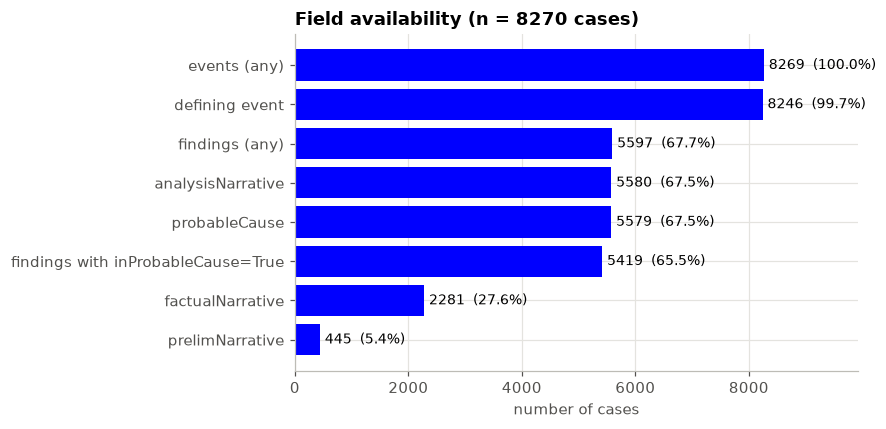

In [605]:
plot_data = availability.drop("total cases").sort_values("cases")
number_of_cases = len(cases_table)

figure, axis = plt.subplots(figsize=(8, 4))
axis.barh(plot_data.index, plot_data["cases"], color="blue")
for position, field_name in enumerate(plot_data.index):
    count = plot_data.loc[field_name, "cases"]
    percentage = plot_data.loc[field_name, "% of cases"]
    axis.text(count + number_of_cases * 0.01, position, f"{int(count)}  ({percentage:.1f}%)",
              va="center", fontsize=9)
axis.set_xlim(0, number_of_cases * 1.2)
axis.set_xlabel("number of cases")
axis.set_title(f"Field availability (n = {number_of_cases} cases)")
plt.tight_layout()
plt.show()

**Overlap between fields:** cases that have both the row field and the column field.

In [606]:
field_names = field_present.columns
overlap = pd.DataFrame(0, index=field_names, columns=field_names)
for row_field in field_names:
    for column_field in field_names:
        has_both = field_present[row_field] & field_present[column_field]
        overlap.loc[row_field, column_field] = has_both.sum()

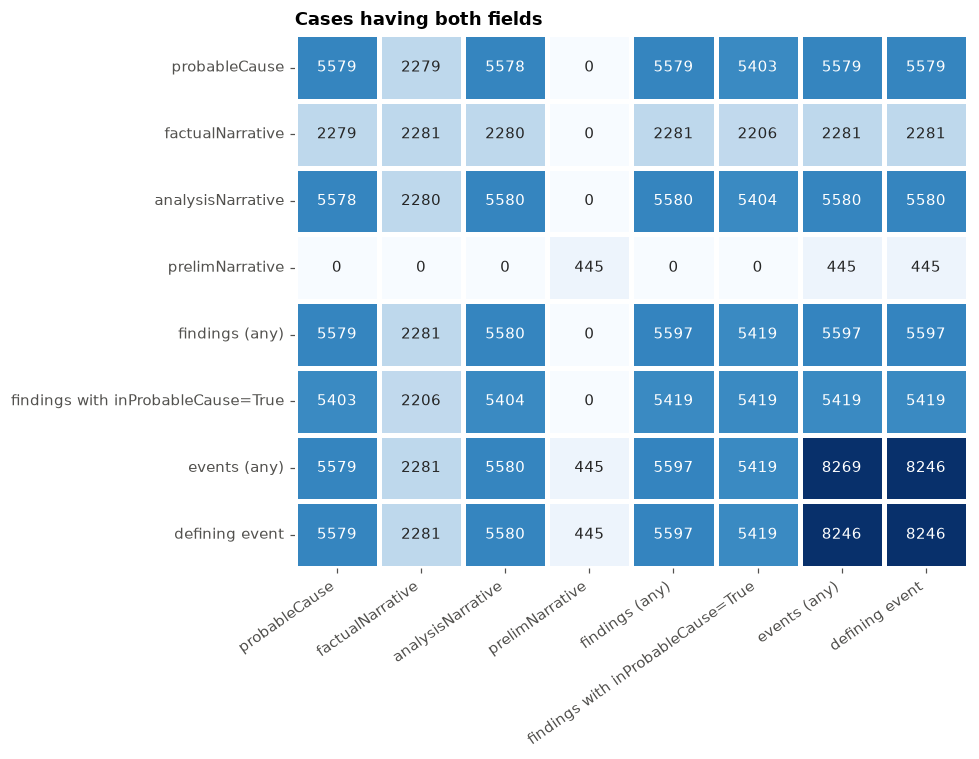

In [607]:
figure, axis = plt.subplots(figsize=(9, 7))
sns.heatmap(overlap, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white", ax=axis)
axis.set_title("Cases having both fields")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 2. Distribution of findings
Findings which appeared in probableCause have `inProbableCause = True`.

In [608]:
print("Total findings:", len(findings_table))
print("Cases with findings:", findings_table["mKey"].nunique())

Total findings: 15873
Cases with findings: 5597


In [609]:
cause_flag_counts = findings_table["inProbableCause"].value_counts(dropna=False).to_frame("findings")
cause_flag_counts["%"] = (cause_flag_counts["findings"] / cause_flag_counts["findings"].sum() * 100).round(1)
cause_flag_counts

,findings,%
inProbableCause,,
True,13544,85.3
False,2329,14.7


In [610]:
findings_per_case = pd.DataFrame()
findings_per_case["all_findings"] = findings_table.groupby("mKey").size()
findings_per_case["cause_findings"] = findings_table.groupby("mKey")["inProbableCause"].sum()

In [611]:
findings_per_case.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
all_findings,5597.0,2.84,1.50,1.0,2.0,3.0,3.0,36.0
cause_findings,5597.0,2.42,1.43,0.0,2.0,2.0,3.0,34.0


In [612]:
def tick_labels(values, limit):
    labels = [str(value) for value in values]
    labels[-1] = f"{limit}+"
    return labels

In [613]:
LIMIT = 8
limited_counts = findings_per_case.clip(upper=LIMIT)
grid = pd.crosstab(limited_counts["all_findings"], limited_counts["cause_findings"])
grid = grid.reindex(index=range(1, LIMIT + 1), columns=range(0, LIMIT + 1), fill_value=0)

In [614]:
hide_cell = pd.DataFrame(False, index=grid.index, columns=grid.columns)
for total_findings in grid.index:
    for cause_findings in grid.columns:
        if cause_findings > total_findings or grid.loc[total_findings, cause_findings] == 0:
            hide_cell.loc[total_findings, cause_findings] = True

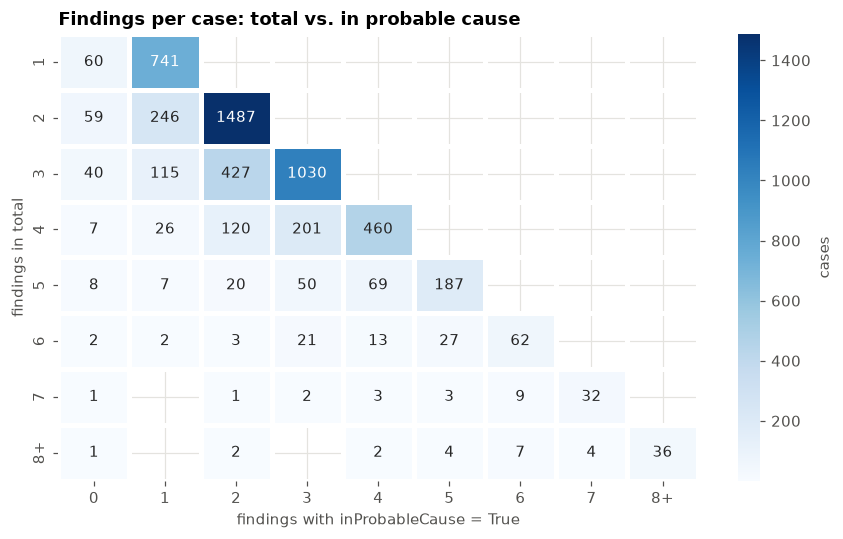

In [615]:
figure, axis = plt.subplots(figsize=(8, 5))
sns.heatmap(grid, mask=hide_cell, annot=True, fmt="d", cmap="Blues",
            cbar_kws={"label": "cases"}, linewidths=2, linecolor="white", ax=axis,
            xticklabels=tick_labels(grid.columns, LIMIT), yticklabels=tick_labels(grid.index, LIMIT))
axis.set_xlabel("findings with inProbableCause = True")
axis.set_ylabel("findings in total")
axis.set_title("Findings per case: total vs. in probable cause")
plt.tight_layout()
plt.show()

### Top categories per tier

In [616]:
def plot_top_values(table, column, flag_column, unit, number_of_values, title):
    top_values = table[column].value_counts().head(number_of_values).index
    top_rows = table[table[column].isin(top_values)]

    counts = pd.crosstab(top_rows[column], top_rows[flag_column] == True)
    counts = counts.reindex(index=top_values[::-1], columns=[True, False], fill_value=0)
    counts.columns = [f"{flag_column} = True", f"{flag_column} = False"]

    axis = counts.plot(kind="barh", stacked=True, color=["orange", "blue"], width=0.7,
                       figsize=(9, 0.3 * len(counts) + 2))
    totals = counts.sum(axis=1)
    for position, total in enumerate(totals):
        axis.text(total + totals.max() * 0.01, position, str(int(total)), va="center", fontsize=9)
    axis.set_xlabel(unit)
    axis.set_ylabel("")
    axis.legend(loc="lower right")
    axis.set_title(title)
    plt.tight_layout()
    plt.show()

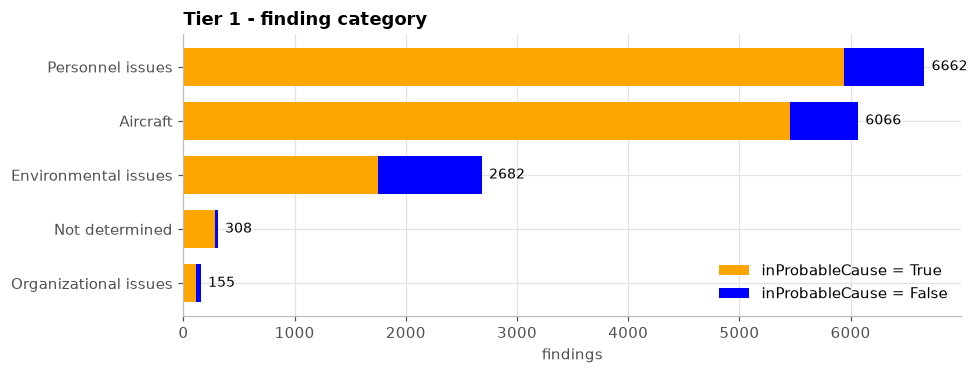

In [617]:
plot_top_values(
    table=findings_table,
    column="tier1Name",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=10,
    title="Tier 1 - finding category",
)

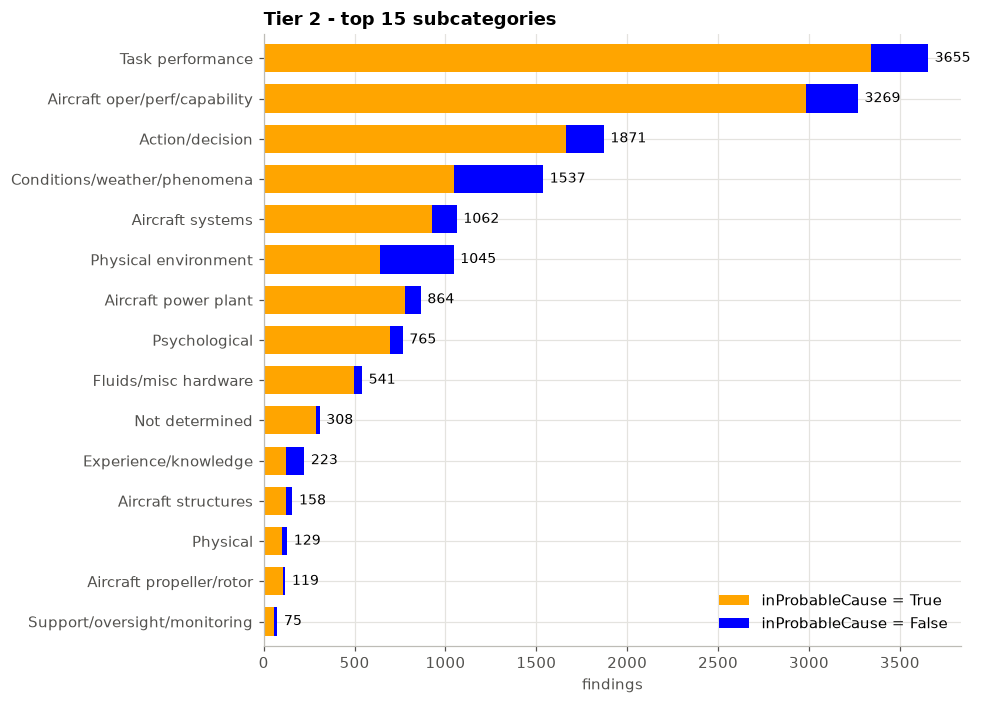

In [618]:
plot_top_values(
    table=findings_table,
    column="tier2Name",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=15,
    title="Tier 2 - top 15 subcategories",
)

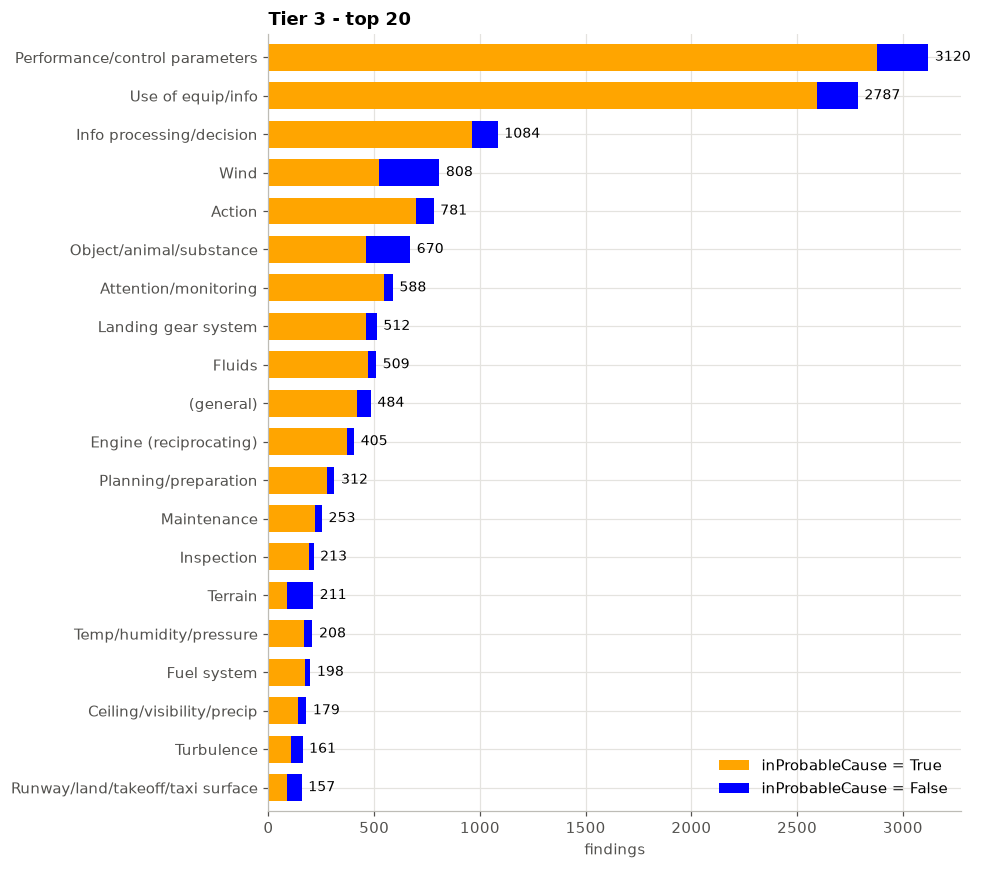

In [619]:
plot_top_values(
    table=findings_table,
    column="tier3Name",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=20,
    title="Tier 3 - top 20",
)

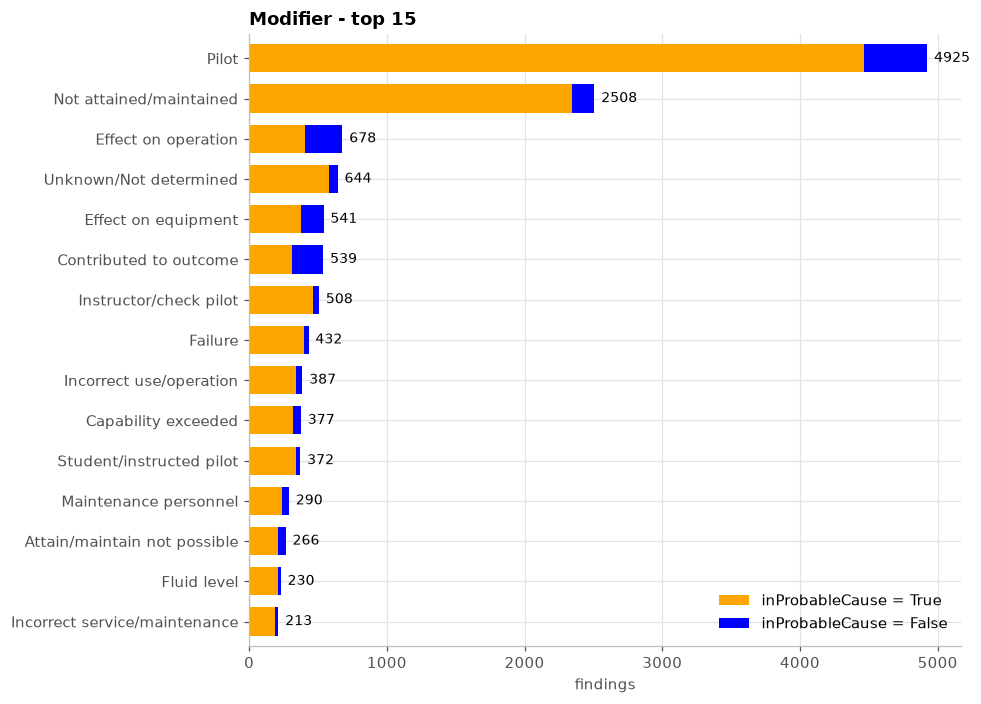

In [620]:
plot_top_values(
    table=findings_table,
    column="modifierName",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=15,
    title="Modifier - top 15",
)

In [621]:
grouped_by_description = findings_table.groupby("findingDescription")

description_summary = pd.DataFrame()
description_summary["findings"] = grouped_by_description.size()
description_summary["cases"] = grouped_by_description["mKey"].nunique()
description_summary["% in probable cause"] = (grouped_by_description["inProbableCause"].mean() * 100).round(0)
description_summary = description_summary.sort_values("findings", ascending=False).head(20)

In [622]:
description_summary

,findings,cases,% in probable cause
findingDescription,,,
Personnel issues-Task performance-Use of equip/info-Aircraft control-Pilot,1896,1895,95.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Directional control-Not attained/maintained,887,887,95.0
Personnel issues-Action/decision-Info processing/decision-Decision making/judgment-Pilot,701,698,92.0
Personnel issues-Task performance-Use of equip/info-Use of equip/system-Pilot,325,325,90.0
Not determined-Not determined-(general)-(general)-Unknown/Not determined,295,294,93.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Airspeed-Not attained/maintained,278,278,94.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Landing flare-Not attained/maintained,247,247,92.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Altitude-Not attained/maintained,238,238,95.0
Personnel issues-Task performance-Use of equip/info-Aircraft control-Student/instructed pilot,207,207,95.0


### All categories per tier summary 

In [623]:
def finding_label(table, level):
    if level == 5:
        return table["findingDescription"]
    label = table["tier1Name"].fillna("")
    for tier in range(2, level + 1):
        label = label + " > " + table[f"tier{tier}Name"].fillna("")
    return label

In [624]:
LEVELS = {1: "tier 1", 2: "tier 1-2", 3: "tier 1-3", 4: "tier 1-4", 5: "full description"}
for level in LEVELS:
    findings_table[f"label_level_{level}"] = finding_label(findings_table, level)

cause_finding_rows = findings_table[findings_table["inProbableCause"] == True]

In [625]:
long_tail_rows = []
for level, level_name in LEVELS.items():
    label_counts = findings_table[f"label_level_{level}"].value_counts()
    cause_label_counts = cause_finding_rows[f"label_level_{level}"].value_counts()
    long_tail_rows.append({
        "level": level_name,
        "distinct labels": len(label_counts),
        "labels with < 5 findings": (label_counts < 5).sum(),
        "labels with >= 20 findings": (label_counts >= 20).sum(),
        "% findings covered by top 10": round(label_counts.head(10).sum() / label_counts.sum() * 100, 1),
        "distinct cause labels": len(cause_label_counts),
    })

In [626]:
pd.DataFrame(long_tail_rows).set_index("level")

,distinct labels,labels with < 5 findings,labels with >= 20 findings,% findings covered by top 10,distinct cause labels
level,,,,,
tier 1,5,0,5,100.0,5
tier 1-2,21,0,20,94.0,21
tier 1-3,123,26,54,71.0,121
tier 1-4,601,309,124,40.6,555
full description,2074,1636,94,33.2,1781


## 3. Distribution of events
Findings which appeared in probableCause have `isDefiningEvent = True` .

In [627]:
print("Total events:", len(events_table))
print("Cases with events:", events_table["mKey"].nunique())

Total events: 14685
Cases with events: 8269


In [628]:
defining_flag_counts = events_table["isDefiningEvent"].value_counts().to_frame("events")
defining_flag_counts["%"] = (defining_flag_counts["events"] / defining_flag_counts["events"].sum() * 100).round(1)

In [629]:
defining_flag_counts

,events,%
isDefiningEvent,,
True,8338,56.8
False,6347,43.2


In [630]:
events_per_case = pd.DataFrame()
events_per_case["all_events"] = events_table.groupby("mKey").size()
events_per_case["defining_events"] = events_table.groupby("mKey")["isDefiningEvent"].sum()

In [631]:
events_per_case.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
all_events,8269.0,1.78,1.09,1.0,1.0,1.0,2.0,9.0
defining_events,8269.0,1.01,0.12,0.0,1.0,1.0,1.0,3.0


In [632]:
defining_events_count = events_per_case["defining_events"].value_counts().sort_index().to_frame("cases")
defining_events_count.index.name = "defining events per case"

In [633]:
defining_events_count

,cases
defining events per case,
0,23
1,8155
2,90
3,1


In [634]:
EVENT_LIMIT = 7
defining_position = defining_event_rows.groupby("mKey")["sequenceNumber"].min()

positions = pd.DataFrame()
positions["all_events"] = events_per_case["all_events"]
positions["defining_position"] = defining_position
positions = positions.dropna().astype(int).clip(upper=EVENT_LIMIT)

In [635]:
grid = pd.crosstab(positions["all_events"], positions["defining_position"])
grid = grid.reindex(index=range(1, EVENT_LIMIT + 1), columns=range(1, EVENT_LIMIT + 1), fill_value=0)

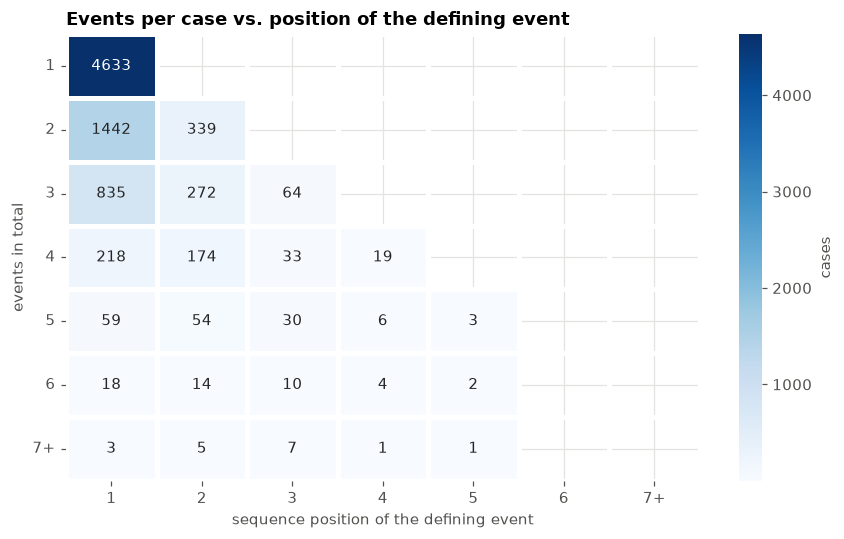

In [636]:
figure, axis = plt.subplots(figsize=(8, 5))
sns.heatmap(grid, mask=(grid == 0), annot=True, fmt="d", cmap="Blues",
            cbar_kws={"label": "cases"}, linewidths=2, linecolor="white", ax=axis,
            xticklabels=tick_labels(grid.columns, EVENT_LIMIT), yticklabels=tick_labels(grid.index, EVENT_LIMIT))
axis.set_xlabel("sequence position of the defining event")
axis.set_ylabel("events in total")
axis.tick_params(axis="y", rotation=0)
axis.set_title("Events per case vs. position of the defining event")
plt.tight_layout()
plt.show()

### Top categories

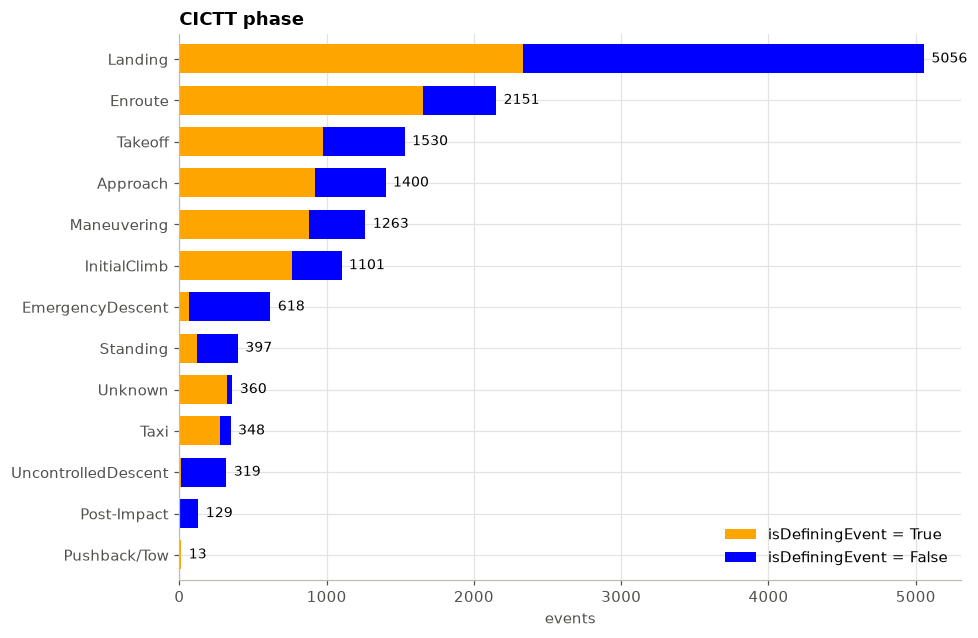

In [637]:
plot_top_values(
    table=events_table,
    column="cicttPhaseSOEGroup",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=15,
    title="CICTT phase",
)

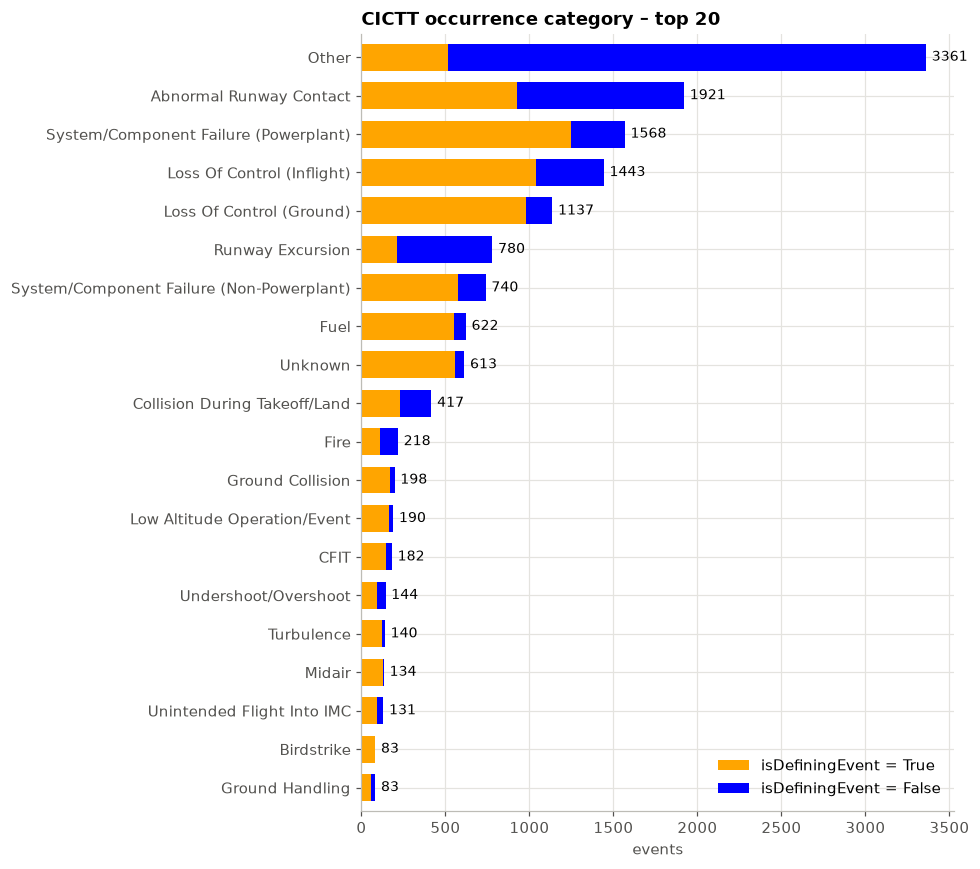

In [638]:
plot_top_values(
    table=events_table,
    column="cicttEventSOEGroup",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=20,
    title="CICTT occurrence category – top 20",
)

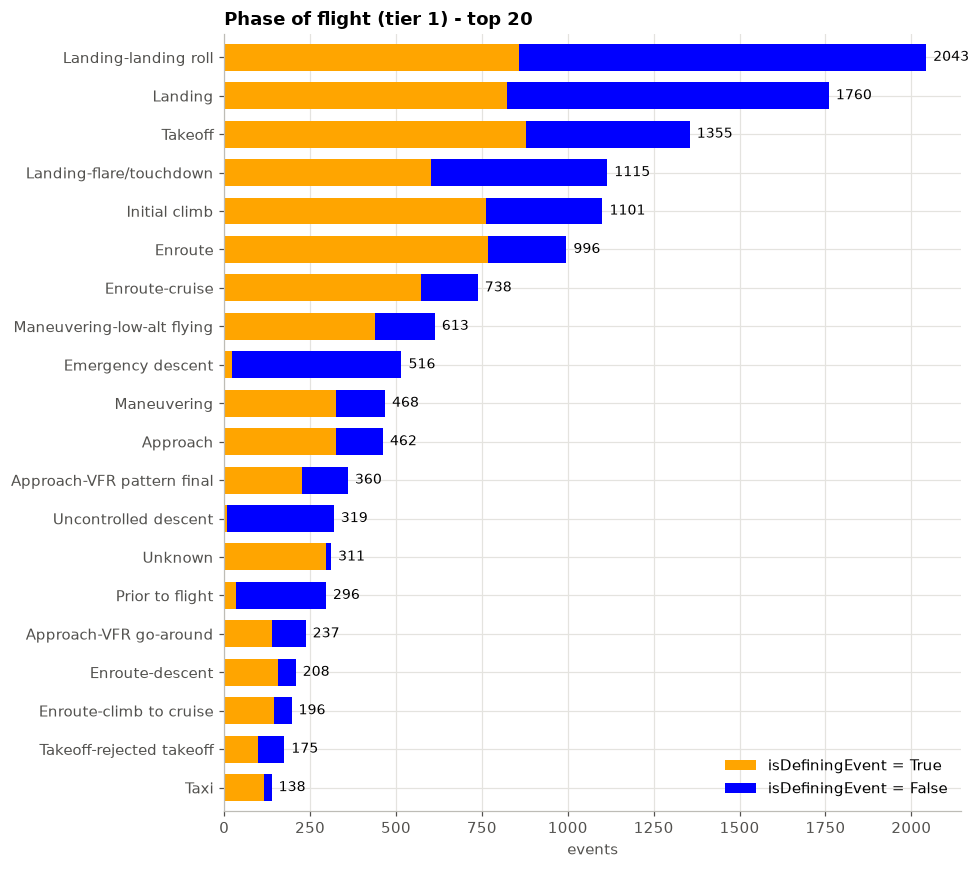

In [639]:
plot_top_values(
    table=events_table,
    column="eventTier1Name",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=20,
    title="Phase of flight (tier 1) - top 20",
)

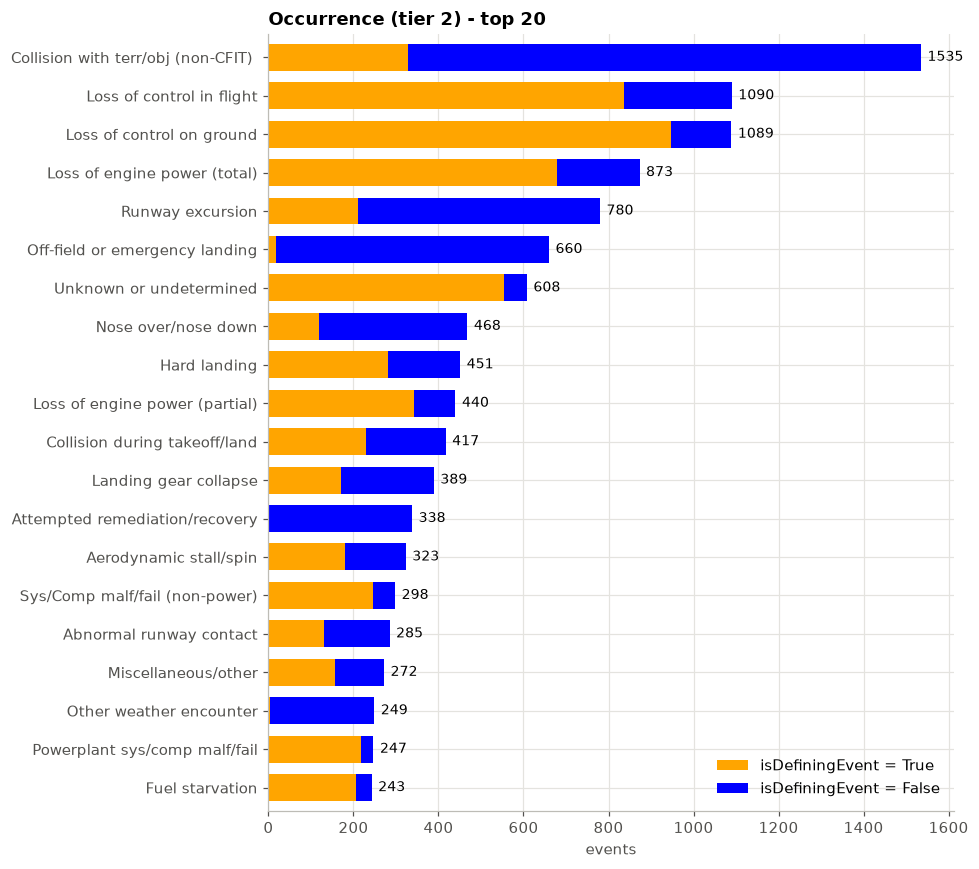

In [640]:
plot_top_values(
    table=events_table,
    column="eventTier2Name",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=20,
    title="Occurrence (tier 2) - top 20",
)

In [641]:
grouped_by_phase_event = events_table.groupby("phaseEvent")

phase_event_summary = pd.DataFrame()
phase_event_summary["events"] = grouped_by_phase_event.size()
phase_event_summary["cases"] = grouped_by_phase_event["mKey"].nunique()
phase_event_summary["% defining"] = (grouped_by_phase_event["isDefiningEvent"].mean() * 100).round(0)
phase_event_summary = phase_event_summary.sort_values("events", ascending=False).head(20)

In [642]:
phase_event_summary

,events,cases,% defining
phaseEvent,,,
Landing-landing roll > Loss of control on ground,512,512,87.0
Landing-landing roll > Runway excursion,455,454,24.0
Uncontrolled descent > Collision with terr/obj (non-CFIT),295,293,1.0
Emergency descent > Off-field or emergency landing,268,268,0.0
Landing-flare/touchdown > Hard landing,255,255,67.0
Landing-landing roll > Nose over/nose down,247,247,26.0
Landing > Collision with terr/obj (non-CFIT),210,210,8.0
Enroute > Loss of engine power (total),204,204,82.0
Landing-landing roll > Collision with terr/obj (non-CFIT),185,185,8.0


### All categories per tier summary 

In [643]:
EVENT_LEVELS = {
    "CICTT phase": "cicttPhaseSOEGroup",
    "CICTT occurrence": "cicttEventSOEGroup",
    "phase (tier 1)": "eventTier1Name",
    "occurrence (tier 2)": "eventTier2Name",
    "phase > occurrence": "phaseEvent",
}

In [644]:
event_long_tail_rows = []
for level_name, column in EVENT_LEVELS.items():
    label_counts = events_table[column].value_counts()
    defining_label_counts = defining_event_rows[column].value_counts()
    event_long_tail_rows.append({
        "level": level_name,
        "distinct labels": len(label_counts),
        "labels with < 5 events": (label_counts < 5).sum(),
        "labels with >= 20 events": (label_counts >= 20).sum(),
        "% events covered by top 10": round(label_counts.head(10).sum() / label_counts.sum() * 100, 1),
        "distinct defining labels": len(defining_label_counts),
        "defining labels with >= 20 cases": (defining_label_counts >= 20).sum(),
    })

In [645]:
pd.DataFrame(event_long_tail_rows).set_index("level")

,distinct labels,labels with < 5 events,labels with >= 20 events,% events covered by top 10,distinct defining labels,defining labels with >= 20 cases
level,,,,,,
CICTT phase,13,0,12,96.9,12,10
CICTT occurrence,36,0,31,85.8,36,28
phase (tier 1),46,4,37,72.9,45,33
occurrence (tier 2),95,7,63,54.4,91,49
phase > occurrence,1113,675,150,19.2,881,93


## 4. Text lengths

In [646]:
WORD_PATTERN = re.compile(r"[A-Za-z0-9]+(?:['’][A-Za-z]+)?")
SENTENCE_END_PATTERN = re.compile(r"[.!?]+(?:\s|$)")


def text_statistics(text):
    characters = len(text)
    words = len(WORD_PATTERN.findall(text))
    sentences = len(SENTENCE_END_PATTERN.findall(text))
    if sentences == 0:
        sentences = 1
    return pd.Series({"characters": characters, "words": words, "sentences": sentences})

In [647]:
LENGTH_FIELDS = ["probableCause", "factualNarrative", "analysisNarrative"]
lengths = {}
for field_name in LENGTH_FIELDS:
    lengths[field_name] = cases_table[field_name].dropna().apply(text_statistics)
lengths["findingDescription"] = findings_table["findingDescription"].dropna().apply(text_statistics)

In [648]:
summary_parts = {}
for field_name, field_lengths in lengths.items():
    summary_parts[field_name] = field_lengths.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T
length_summary = pd.concat(summary_parts)

In [649]:
length_summary.round(1)

count    mean     std    min     25%     50%     75%      95%      max
probableCause      characters   5579.0   150.7    93.2   12.0    96.0   131.0   179.0    305.0   2445.0
                   words        5579.0    23.7    14.3    2.0    15.0    21.0    28.0     47.0    356.0
                   sentences    5579.0     1.2     0.4    1.0     1.0     1.0     1.0      2.0      7.0
factualNarrative   characters   2281.0  5879.9  5497.4  368.0  2553.0  4142.0  7336.0  15568.0  63346.0
                   words        2281.0   966.9   902.9   55.0   420.0   681.0  1203.0   2563.0  10454.0
                   sentences    2281.0    47.0    40.1    3.0    21.0    34.0    59.0    119.0    398.0
analysisNarrative  characters   5580.0  1357.4  1279.6  105.0   652.8   975.0  1619.2   3449.2  36500.0
                   words        5580.0   220.2   206.4   17.0   105.0   160.0   266.0    558.0   5879.0
                   sentences    5580.0     9.7     7.7    1.0     5.0     7.0    12.0     23.0    182.0
findingDescription characters  15871.0    88.9    16.3   51.0    74.0    88.0   102.0    114.0    135.0
                   words       15871.0    11.2     1.9    6.0    10.0    11.0    13.0     14.0     18.0
                   sentences   15871.0     1.0     0.0    1.0     1.0     1.0     1.0      1.0      1.0

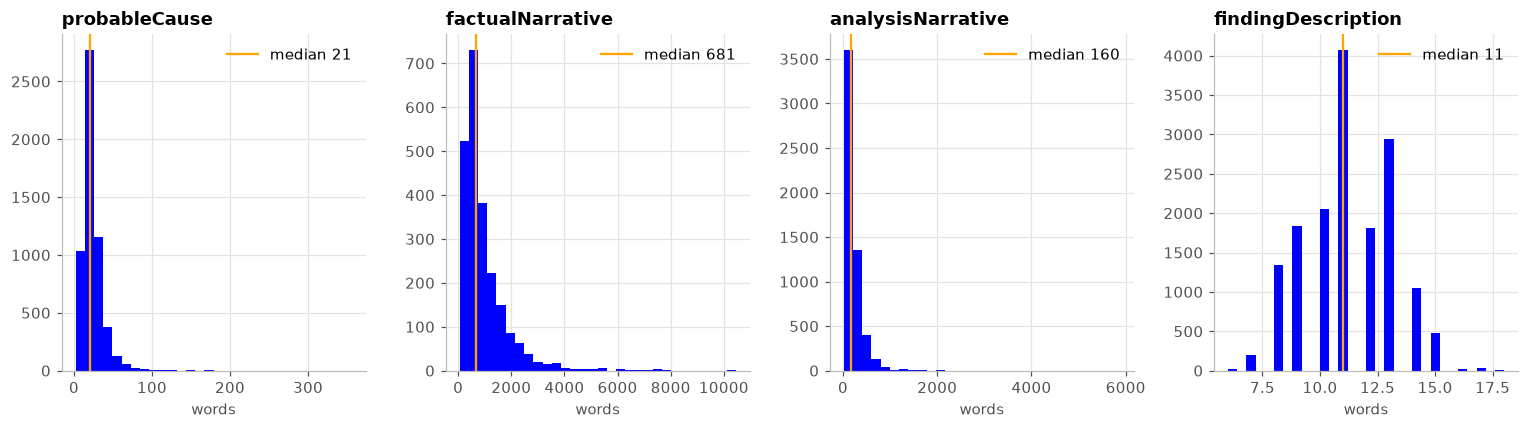

In [650]:
figure, axes = plt.subplots(1, 4, figsize=(14, 4))
for axis, field_name in zip(axes, lengths):
    word_counts = lengths[field_name]["words"]
    axis.hist(word_counts, bins=30, color="blue")
    axis.axvline(word_counts.median(), color="orange", label=f"median {word_counts.median():.0f}")
    axis.legend()
    axis.set_title(field_name)
    axis.set_xlabel("words")
plt.tight_layout()
plt.show()


### Shortest and longest texts

In [651]:
def shorten(text, maximum_length):
    if len(text) > maximum_length:
        return text[:maximum_length] + " …"
    return text

In [652]:
probable_causes = cases_table.dropna(subset=["probableCause"]).copy()
probable_causes["words"] = lengths["probableCause"]["words"]

In [653]:
print("===== SHORTEST probable causes =====")
for _, row in probable_causes.nsmallest(5, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {row['probableCause']}\n")

===== SHORTEST probable causes =====
[CEN25LA070, 2 words] Bird strike.

[DCA21LA120, 3 words] a bird strike.

[ERA22LA375, 3 words] The pilot's suicide.

[DCA22LA198, 5 words] An encounter with convective turbulence.

[DCA23LA067, 5 words] Multiple bird strikes during descent.



In [654]:
print("===== LONGEST probable causes =====")
for _, row in probable_causes.nlargest(2, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {row['probableCause']}\n")

===== LONGEST probable causes =====
[DCA25MA108, 356 words] The Federal Aviation Administration’s (FAA) placement of a helicopter route in close proximity to a runway approach path; their failure to regularly review and evaluate helicopter routes and available data, and their failure to act on recommendations to mitigate the risk of a midair collision near Ronald Reagan Washington National Airport (DCA); as well as the air traffic system’s overreliance on visual separation in order to promote efficient traffic flow without consideration for the limitations of the see-and-avoid concept. Also causal was the lack of effective pilot-applied visual separation by the helicopter crew, which resulted in a midair collision. Additional causal factors were the tower team’s loss of situation awareness and degraded performance due to the high workload of the combined helicopter and local control positions and the absence of a risk assessment process to identify and mitigate real-time operational ri

In [655]:
factual_narratives = cases_table.dropna(subset=["factualNarrative"]).copy()
factual_narratives["words"] = lengths["factualNarrative"]["words"]

In [656]:
print("===== SHORTEST factual narratives =====")
for _, row in factual_narratives.nsmallest(3, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['factualNarrative'], 600)}\n")

===== SHORTEST factual narratives =====
[CEN21LA166, 55 words] The pilot of the personal flight stated that the airplane encountered an “updraft” during a landing flare, which he compensated for, but the airplane bounced twice and experienced a hard landing. The airplane sustained substantial damage to the fuselage. The pilot stated there was no mechanical malfunction/failure that would have precluded normal airplane operation.

[CEN22LA212, 87 words] The private pilot of the personal flight stated that during landing touchdown, there was a small bounce of the airplane, and the right wing lifted. The stall warning annunciated as the pilot applied full right aileron into the crosswind. The airplane then yawed right, and the pilot applied full left rudder and initiated a go-around. The airplane then impacted terrain and sustained substantial damage to both wings and wing struts. The pilot was uninjured. The pilot stated there was no mechanical malfunction/failure of the airplane.

[CEN21

In [657]:
print("===== LONGEST factual narratives =====")
for _, row in factual_narratives.nlargest(1, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['factualNarrative'], 600)}\n")

===== LONGEST factual narratives =====
[DCA21FA174, 10454 words] The search for the airplane began on the day after the accident, July 3, 2021. The aft fuselage was located on July 7 about 0.13 miles north-northwest of the last recorded FAA automatic dependent surveillance-broadcast data point. The aft fuselage (with both wings and the tail still attached, as shown in figure 5) was found on a sloped area of the seafloor with the forward end at a depth of about 340 ft and the tail at a depth of about 363 ft. On July 8, several more parts of the airplane were located, including the forward fuselage (see figure 6), engine cores, thrust reversers, inlet cowls,  …



In [658]:
analysis_narratives = cases_table.dropna(subset=["analysisNarrative"]).copy()
analysis_narratives["words"] = lengths["analysisNarrative"]["words"]

In [659]:
print("===== SHORTEST analysis narratives =====")
for _, row in analysis_narratives.nsmallest(3, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['analysisNarrative'], 600)}\n")

===== SHORTEST analysis narratives =====
[ERA21LA198, 17 words] A stuck right brake during landing, which resulted in a loss of directional control and runway excursion.

[WPR25LA077, 32 words] The investigation of this event is being conducted under the jurisdiction of the Federal Bureau of Investigation (FBI). The NTSB does not plan to issue a report or open a public docket.

[CEN23LA203, 34 words] While on initial climb, a bird impacted the leading edge of the vertical stabilizer. The leading edge of the stabilizer sustained substantial damage. The airplane was controllable, and the pilot executed an uneventful landing.



In [660]:
print("===== LONGEST analysis narratives =====")
for _, row in analysis_narratives.nlargest(1, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['analysisNarrative'], 600)}\n")

===== LONGEST analysis narratives =====
[DCA21FA174, 5879 words] Transair flight 810, a Title 14 Code of Federal Regulations Part 121 cargo flight, experienced a partial loss of power involving the right engine shortly after takeoff and a water ditching in the Pacific Ocean about 11.5 minutes later. This analysis summarizes the accident and evaluates (1) the right engine partial loss of power, (2) the captain's communications with air traffic control (ATC) and the first officer's left and right engine thrust reductions, (3) the first officer's misidentification of the affected engine and the captain's failure to verify the information, (4) checklist perform …



## 5. Cases without text

In [661]:
def availability_by(column):
    """Share of cases with each text field, findings and events, per value of `column`."""
    groups = cases_table.groupby(column, dropna=False)
    cases_per_group = groups.size()

    result = pd.DataFrame()
    result["cases"] = cases_per_group
    result["% probableCause"] = groups["probableCause"].count() / cases_per_group * 100
    result["% factualNarrative"] = groups["factualNarrative"].count() / cases_per_group * 100
    result["% analysisNarrative"] = groups["analysisNarrative"].count() / cases_per_group * 100
    result["% cause findings"] = groups["hasCauseFindings"].mean() * 100
    result["% events"] = groups["hasEvents"].mean() * 100
    result["% defining event"] = groups["hasDefiningEvent"].mean() * 100
    return result.sort_values("cases", ascending=False).round(1)

In [662]:
availability_by("completionStatus")

,cases,% probableCause,% factualNarrative,% analysisNarrative,% cause findings,% events,% defining event
completionStatus,,,,,,,
Completed,5581,100.0,40.9,100.0,96.8,100.0,100.0
N/A,2235,0.0,0.0,0.0,0.6,100.0,98.9
Ongoing,454,0.0,0.0,0.0,0.0,100.0,100.0


In [663]:
availability_by("eventType")

,cases,% probableCause,% factualNarrative,% analysisNarrative,% cause findings,% events,% defining event
eventType,,,,,,,
Accident,7397,74.6,30.2,74.6,72.5,100.0,99.8
Incident,787,7.5,5.6,7.5,7.0,100.0,98.9
Occurrence,86,3.5,3.5,3.5,3.5,100.0,97.7


In [664]:
availability_by("investigationClass")

,cases,% probableCause,% factualNarrative,% analysisNarrative,% cause findings,% events,% defining event
investigationClass,,,,,,,
Class 4 - Basic report with no Prelim publish,3469,95.4,0.5,95.4,92.5,100.0,100.0
Class 3,2774,80.7,80.8,80.8,78.2,100.0,100.0
Class 5 - No publish,1985,0.0,0.0,0.0,0.6,99.9,98.8
Class 2,29,75.9,75.9,75.9,75.9,100.0,100.0
Class 1,9,88.9,11.1,77.8,88.9,100.0,100.0
NaN,4,0.0,0.0,0.0,0.0,100.0,100.0


## 6. Sample texts

In [665]:
has_both_texts = cases_table["probableCause"].notna() & cases_table["factualNarrative"].notna()
samples = cases_table[has_both_texts].sample(10, random_state=43)

In [666]:
for _, case in samples.iterrows():
    case_findings = findings_table[findings_table["mKey"] == case["mKey"]]
    case_events = events_table[events_table["mKey"] == case["mKey"]]
    case_events = case_events.sort_values(["aircraftNumber", "sequenceNumber"])

    print("=" * 100)
    print(f"{case['ntsbNumber']} | {case['eventDate']} | {case['highestInjuryLevel']} injury")
    print("\nPROBABLE CAUSE:\n", case["probableCause"])
    print("\nANALYSIS NARRATIVE (first 800 characters):\n", shorten(case["analysisNarrative"], 800))
    print("\nFACTUAL NARRATIVE (first 800 characters):\n", shorten(case["factualNarrative"], 800))

    print("\nFINDINGS:")
    for _, finding in case_findings.iterrows():
        if finding["inProbableCause"]:
            marker = "CAUSE"
        else:
            marker = "     "
        print(f"  [{marker}] {finding['findingDescription']}")

    print("\nEVENTS:")
    for _, event in case_events.iterrows():
        if event["isDefiningEvent"]:
            marker = "DEFINING"
        else:
            marker = "        "
        print(f"  [{marker}] {event['sequenceNumber']}. {event['eventTier1Name']} – "
              f"{event['eventTier2Name']} ({event['cicttEventSOEGroup']})")

ERA22FA105 | 2022-01-11 | Serious injury

PROBABLE CAUSE:
 An inflight attitude upset for undetermined reasons that resulted in a rotor system overspeed, a reduction of power from both engines, and a subsequent hard landing.

ANALYSIS NARRATIVE (first 800 characters):
 Flight track data from the helicopter air ambulance flight indicated that, while in cruise flight at an altitude of about 1,500 ft mean sea level (msl), the helicopter departed normal cruise flight with an abrupt increase in altitude, followed by a dive. The recovered data from various sources onboard the helicopter did not contain information as to whether the helicopter rolled inverted during this altitude excursion, as recalled by the crewmembers. Surveillance video showed the helicopter in a near-vertical, nose-down, spiraling descent. The pilot arrested the rotation and recovered the helicopter from the dive but was unable to climb or hover due to insufficient engine power, thereby resulting in a hard landing to a c

## 7. Vocabulary

In [667]:
VOCABULARY_FIELDS = ["probableCause", "factualNarrative", "analysisNarrative"]

In [668]:
def count_terms(texts, ngram_range):
    vectorizer = CountVectorizer(stop_words="english", ngram_range=ngram_range)
    matrix = vectorizer.fit_transform(texts)
    counts = pd.Series(matrix.sum(axis=0).tolist()[0], index=vectorizer.get_feature_names_out())
    return counts.sort_values(ascending=False)

In [669]:
word_counts = {}
bigram_counts = {}
for field_name in VOCABULARY_FIELDS:
    texts = cases_table[field_name].dropna()
    word_counts[field_name] = count_terms(texts, (1, 1))
    bigram_counts[field_name] = count_terms(texts, (2, 2))

In [670]:
vocabulary_rows = []
for field_name in VOCABULARY_FIELDS:
    counts = word_counts[field_name]
    vocabulary_rows.append({
        "field": field_name,
        "vocabulary size": len(counts),
        "words seen once": (counts == 1).sum(),
        "% vocabulary seen once": round((counts == 1).mean() * 100, 1),
    })

In [671]:
pd.DataFrame(vocabulary_rows).set_index("field")

,vocabulary size,words seen once,% vocabulary seen once
field,,,
probableCause,3572,1451,40.6
factualNarrative,31641,12585,39.8
analysisNarrative,14669,4754,32.4


In [672]:
def plot_top_terms(field_name, colour):
    figure, axes = plt.subplots(1, 2, figsize=(12, 6))
    word_counts[field_name].head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color=colour,
                                                     title=f"Top 20 words – {field_name}")
    bigram_counts[field_name].head(20).iloc[::-1].plot(kind="barh", ax=axes[1], color=colour,
                                                       title=f"Top 20 bigrams – {field_name}")
    plt.tight_layout()
    plt.show()

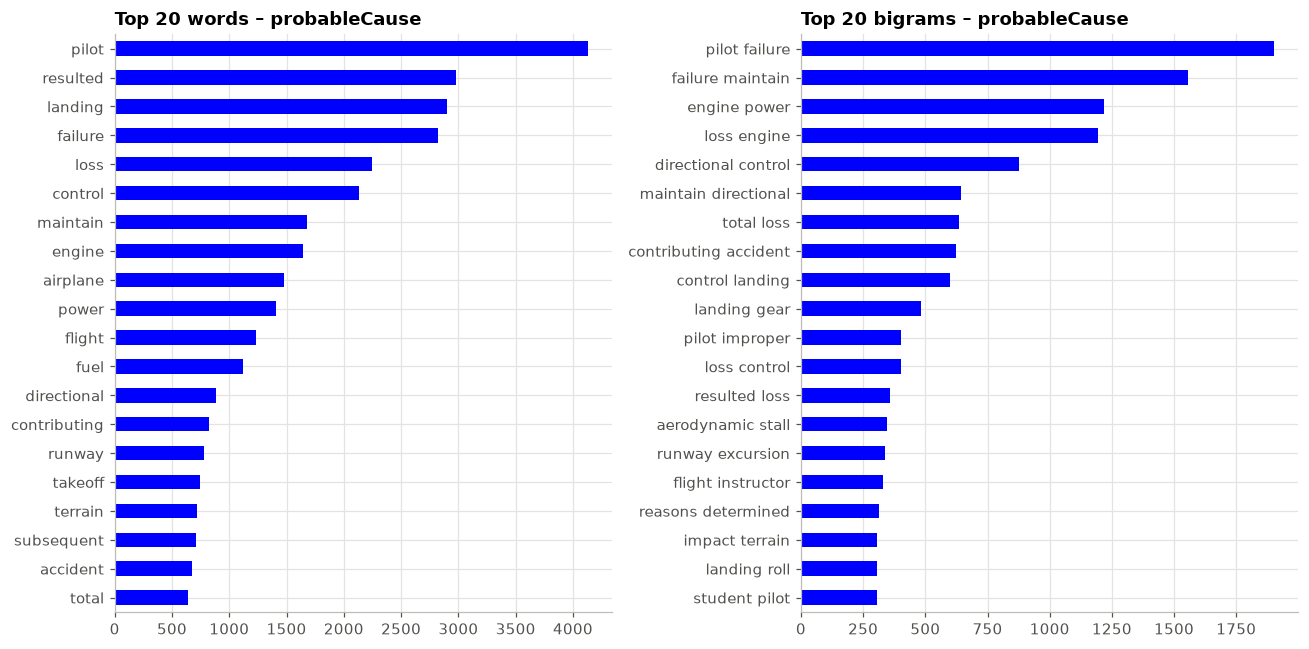

In [673]:
plot_top_terms("probableCause", "blue")

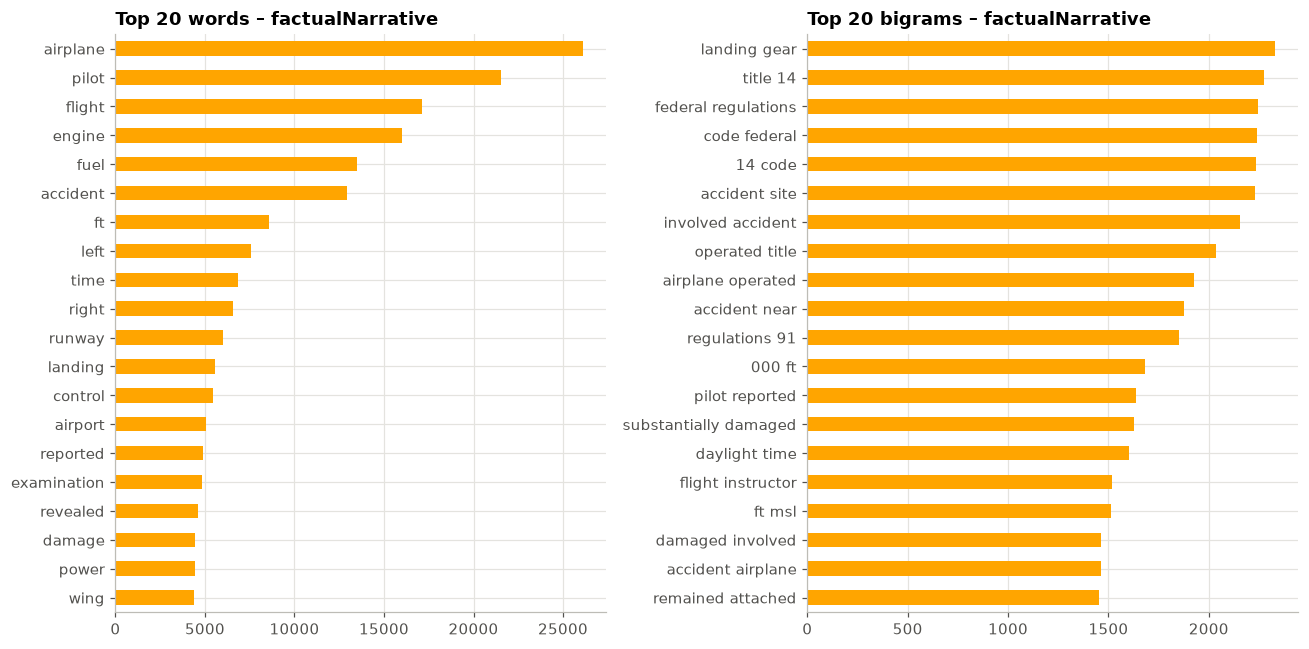

In [674]:
plot_top_terms("factualNarrative", "orange")

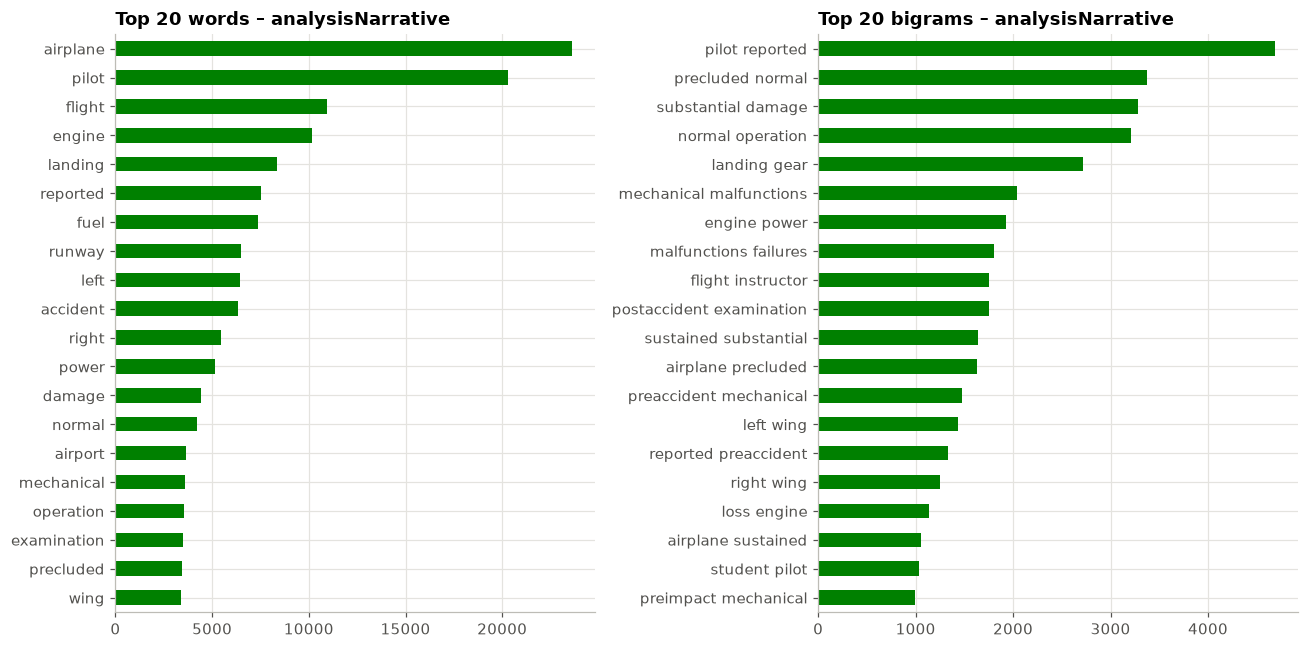

In [675]:
plot_top_terms("analysisNarrative", "green")